## Setup

In [ ]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent))

from src.load import load_raw_data
from src.clean import daten_bereinigen
from src.merge import merge_dfs
from src.transform import berechne_kennzahlen

gemeinden, _ = berechne_kennzahlen(merge_dfs(*daten_bereinigen(*load_raw_data())))

ANTRIEBE = ["Elektro", "Hybrid", "Benzin", "Diesel"]
DICHTEKLASSEN = ["tief", "mittel-tief", "mittel-hoch", "hoch"]

gemeinden["Elektro"] = gemeinden["antrieb_elektrisch"]
gemeinden["Hybrid"] = gemeinden["antrieb_normal_hybrid"] + gemeinden["antrieb_plugin_hybrid"]
gemeinden["Benzin"] = gemeinden["antrieb_benzin"]
gemeinden["Diesel"] = gemeinden["antrieb_diesel"]

# Long-Format: eine Zeile pro Gemeinde, Jahr und Antriebsart
daten = gemeinden.melt(
    id_vars=["gemeinde_nr", "Gemeinde", "Jahr", "einwohner_je_km2", "pkw"],
    value_vars=ANTRIEBE,
    var_name="Antriebsart",
    value_name="Fahrzeuge",
).rename(columns={"einwohner_je_km2": "Einwohnerdichte"})
daten["Anteil"] = daten["Fahrzeuge"] / daten["pkw"] * 100

# Feste Dichteklassen nach 2024 (je 40 Gemeinden)
dichte_2024 = gemeinden[gemeinden["Jahr"] == 2024].set_index("gemeinde_nr")["einwohner_je_km2"]
daten["Dichteklasse"] = daten["gemeinde_nr"].map(pd.qcut(dichte_2024, q=4, labels=DICHTEKLASSEN))

FARBEN = {"Elektro": "#2a78d6", "Hybrid": "#eb6834", "Benzin": "#1baf7a", "Diesel": "#eda100"}
FARBEN_DICHTE = dict(zip(DICHTEKLASSEN, ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]))

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e5e5e5",
    "lines.linewidth": 2,
})


def linien_beschriften(ax, tabelle):
    """Schreibt den Namen jeder Linie an ihr Ende."""
    for spalte in tabelle.columns:
        ax.annotate(spalte, (tabelle.index[-1], tabelle[spalte].iloc[-1]),
                    xytext=(6, 0), textcoords="offset points", va="center", color="#333333")

## Antriebsarten in der Kanton Zürich

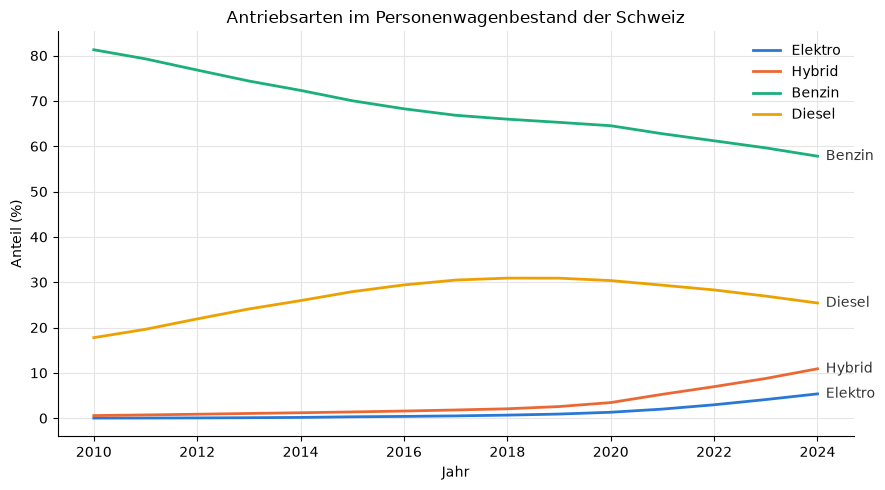

In [ ]:
total = daten.groupby(["Jahr", "Antriebsart"])["Fahrzeuge"].sum().unstack()
pkw_total = gemeinden.groupby("Jahr")["pkw"].sum()
anteile_ch = total[ANTRIEBE].div(pkw_total, axis=0) * 100

fig, ax = plt.subplots()
for antrieb in ANTRIEBE:
    ax.plot(anteile_ch.index, anteile_ch[antrieb], color=FARBEN[antrieb], label=antrieb)
linien_beschriften(ax, anteile_ch)
ax.set(title="Antriebsarten im Personenwagenbestand der Schweiz", xlabel="Jahr", ylabel="Anteil (%)")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## Elektroanteil nach Dichteklasse

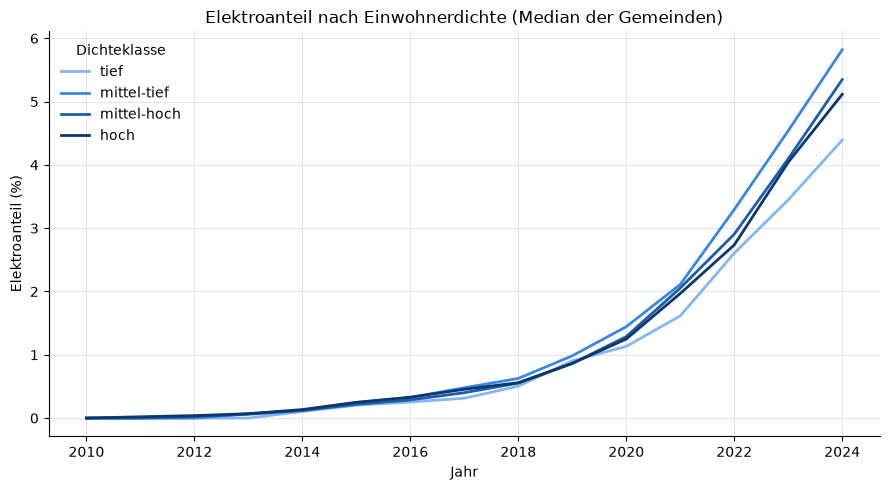

In [9]:
elektro = daten[daten["Antriebsart"] == "Elektro"]
elektro_dichte = elektro.groupby(["Jahr", "Dichteklasse"], observed=True)["Anteil"].median().unstack()

fig, ax = plt.subplots()
for klasse in DICHTEKLASSEN:
    ax.plot(elektro_dichte.index, elektro_dichte[klasse], color=FARBEN_DICHTE[klasse], label=klasse)
ax.set(title="Elektroanteil nach Einwohnerdichte (Median der Gemeinden)", xlabel="Jahr", ylabel="Elektroanteil (%)")
ax.legend(title="Dichteklasse", frameon=False)
plt.tight_layout()
plt.show()

## Alle Antriebe nach Einwohnerdichte 2010 gegenüber 2024

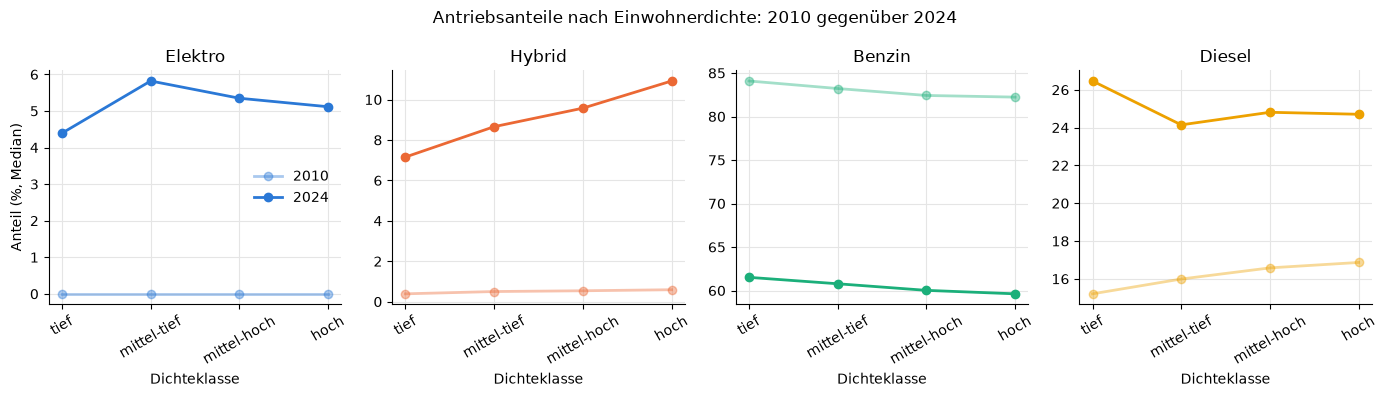

In [10]:
vergleich = (
    daten[daten["Jahr"].isin([2010, 2024]) & daten["Antriebsart"].isin(ANTRIEBE)]
    .groupby(["Antriebsart", "Jahr", "Dichteklasse"], observed=True)["Anteil"]
    .median()
)

fig, achsen = plt.subplots(1, 4, figsize=(14, 4))
for ax, antrieb in zip(achsen, ANTRIEBE):
    for jahr, deckkraft in [(2010, 0.4), (2024, 1.0)]:
        werte = vergleich[antrieb][jahr][DICHTEKLASSEN]
        ax.plot(DICHTEKLASSEN, werte, marker="o", color=FARBEN[antrieb], alpha=deckkraft, label=str(jahr))
    ax.set(title=antrieb, xlabel="Dichteklasse")
    ax.tick_params(axis="x", rotation=30)
achsen[0].set_ylabel("Anteil (%, Median)")
achsen[0].legend(frameon=False)
fig.suptitle("Antriebsanteile nach Einwohnerdichte: 2010 gegenüber 2024")
plt.tight_layout()
plt.show()

## Veränderung Zusammenhang

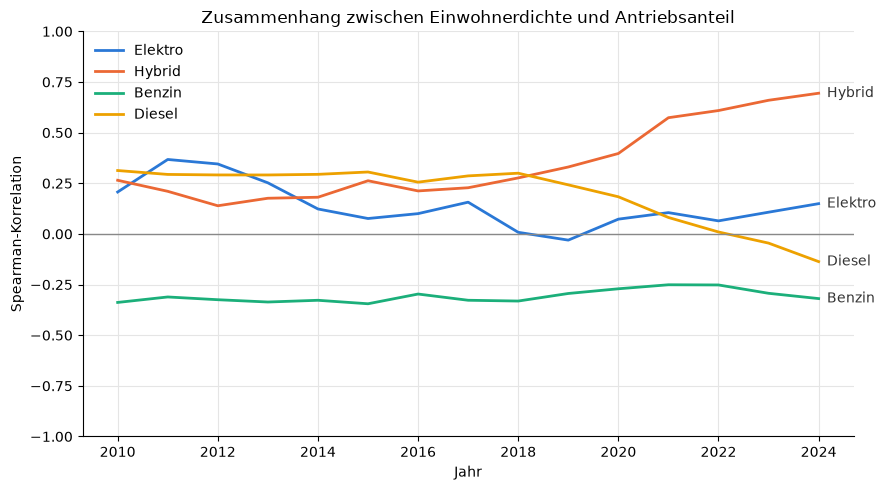

In [11]:
korrelation = (
    daten[daten["Antriebsart"].isin(ANTRIEBE)]
    .groupby(["Jahr", "Antriebsart"])[["Einwohnerdichte", "Anteil"]]
    .corr(method="spearman")
    .xs("Einwohnerdichte", level=2)["Anteil"]
    .unstack()[ANTRIEBE]
)

fig, ax = plt.subplots()
for antrieb in ANTRIEBE:
    ax.plot(korrelation.index, korrelation[antrieb], color=FARBEN[antrieb], label=antrieb)
linien_beschriften(ax, korrelation)
ax.axhline(0, color="#888888", linewidth=1)
ax.set(title="Zusammenhang zwischen Einwohnerdichte und Antriebsanteil", xlabel="Jahr",
       ylabel="Spearman-Korrelation", ylim=(-1, 1))
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## Streudiagramm 2024

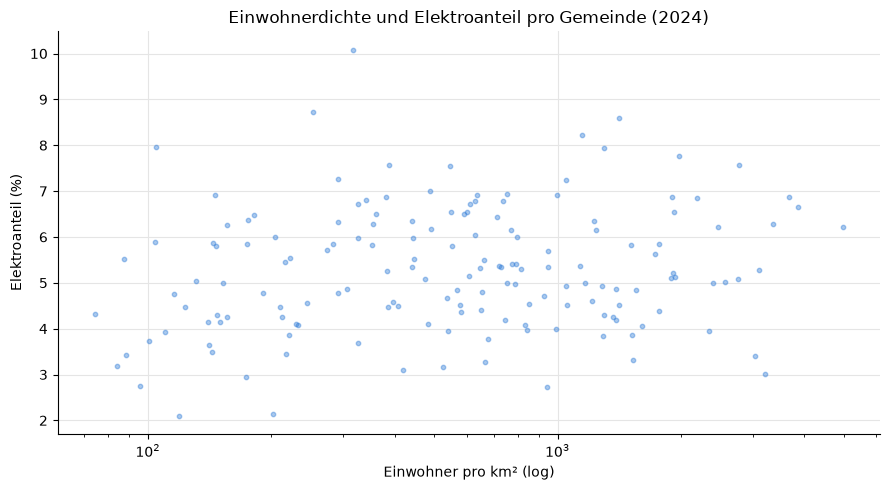

In [12]:
elektro_2024 = elektro[elektro["Jahr"] == 2024]

fig, ax = plt.subplots()
ax.scatter(elektro_2024["Einwohnerdichte"], elektro_2024["Anteil"], s=10, alpha=0.4, color=FARBEN["Elektro"])
ax.set_xscale("log")
ax.set(title="Einwohnerdichte und Elektroanteil pro Gemeinde (2024)",
       xlabel="Einwohner pro km² (log)", ylabel="Elektroanteil (%)")
plt.tight_layout()
plt.show()

## Erkenntnisse

- Hybrid und Elektro sind in dichteren Gemeinden häufiger (Spearman 2024: Hybrid 0.46, Elektro 0.28). Beim Elektroanteil liegen die dünn besiedelten Gemeinden zurück: 3.0 % gegenüber etwa 4.1 % (Median).
- Diesel ist auf dem Land häufiger, und dieser Unterschied wird grösser (Spearman −0.12 im Jahr 2010, −0.29 im Jahr 2024).
- Bei Benzin gibt es kaum einen Zusammenhang mit der Dichte (Spearman nahe 0).